In [1]:
from concurrent.futures import ThreadPoolExecutor
from collections import deque

import numpy as np
import rasterio
from rasterio.windows import Window
from rasterio.warp import reproject, Resampling
from scipy.ndimage import minimum_filter

In [2]:
def get_windows(
    visual_tiff_url,
    window_width=520,
    window_height=520,
):
    """Yield tile IDs and Rasterio windows covering a visual TIFF."""
    if window_width <= 0 or window_height <= 0:
        raise ValueError("Window width and height must be positive.")

    with rasterio.open(visual_tiff_url) as src:
        image_width = src.width
        image_height = src.height

    tile_number = 0

    for row, y in enumerate(range(0, image_height, window_height)):
        for col, x in enumerate(range(0, image_width, window_width)):
            width = min(window_width, image_width - x)
            height = min(window_height, image_height - y)

            yield {
                "tile_id": f"r{row:05d}_c{col:05d}_n{tile_number:08d}",
                "row": row,
                "col": col,
                "window": Window(x, y, width, height),
            }

            tile_number += 1

In [3]:
def read_tile_with_halo(src, tile, halo):
    """Read one tile plus surrounding pixels, and return the RGB array.
    OUTPUT: rgb array with halo, initial tile slice without halo
    """
    window = tile["window"]

    # Expand the read area, keeping it inside the image bounds.
    x_start = max(0, int(window.col_off) - halo)
    y_start = max(0, int(window.row_off) - halo)
    x_end = min(src.width, int(window.col_off + window.width) + halo)
    y_end = min(src.height, int(window.row_off + window.height) + halo)

    read_window = Window(
        x_start,
        y_start,
        x_end - x_start,
        y_end - y_start,
    )

    # Rasterio returns (bands, height, width); rearrange to (height, width, bands).
    bands = src.read([1, 2, 3], window=read_window) # CHECK CHECK CHECK check the bands that the inital image have
    rgb = np.moveaxis(bands, 0, -1)

    # Find the original tile's position inside the larger, halo-inclusive array.
    row_start = int(window.row_off) - y_start
    col_start = int(window.col_off) - x_start

    tile_slice = (
        slice(row_start, row_start + int(window.height)), #rows
        slice(col_start, col_start + int(window.width)), #cols
    )

    return rgb, tile_slice

In [4]:
def dark_channel(rgb_tile, window_size=15):
    """Calculate the dark channel for an RGB tile."""
    if window_size <= 0 or window_size % 2 == 0:
        raise ValueError("window_size must be a positive odd number.")

    # For each pixel, take its darkest RGB value. basically becomes a 2d grayscale for all pixels
    pixel_min = np.min(rgb_tile, axis=2)

    # For each pixel, take the darkest value in its neighborhood.
    return minimum_filter(pixel_min, size=window_size, mode="nearest")

In [5]:
def make_cloud_mask(rgb_with_halo, tile_slice, window_size=15, threshold=180):
    """Create a binary cloud mask for the original tile."""
    dark = dark_channel(rgb_with_halo, window_size)
    dark = dark[tile_slice] # crop back to initial tile size

    # 1 means cloud; 0 means clear.
    return (dark >= threshold).astype(np.uint8)

In [6]:
def resample_mask_to_label_grid(mask_path, label_path, output_path):
    """Resample a predicted mask to match the labeled GeoTIFF's grid."""
    with rasterio.open(mask_path) as mask_src, \
         rasterio.open(label_path) as label_src:

        # Use the label's dimensions and geospatial grid for the output.
        output_profile = label_src.profile.copy()
        output_profile.update(
            count=1,
            dtype="uint8",
            nodata=255,
            compress="deflate",
            photometric="MINISBLACK",
        )

        with rasterio.open(output_path, "w", **output_profile) as dst:
            reproject(
                source=rasterio.band(mask_src, 1),
                destination=rasterio.band(dst, 1),
                src_transform=mask_src.transform,
                src_crs=mask_src.crs,
                dst_transform=label_src.transform,
                dst_crs=label_src.crs,
                src_nodata=mask_src.nodata,
                dst_nodata=255,
                resampling=Resampling.nearest,
            )

    return output_path

In [7]:
import tempfile
from pathlib import Path

def generate_cloud_mask(
    visual_tiff_url,
    label_tiff_url,
    output_path,
    window_width=520,
    window_height=520,
    window_size=15,
    threshold=180,
):
    """Generate a cloud mask and resample it to the label TIFF's grid."""
    if window_size <= 0 or window_size % 2 == 0:
        raise ValueError("window_size must be a positive odd number.")

    halo = window_size // 2

    # Create the full-resolution mask temporarily.
    with tempfile.TemporaryDirectory() as temp_dir:
        full_res_mask_path = str(Path(temp_dir) / "full_res_mask.tif")

        with rasterio.open(visual_tiff_url) as src:
            if src.count != 3:
                raise ValueError(
                    "The visual TIFF must have at least 3 RGB bands."
                )

            # This temporary mask uses the visual TIFF's grid.
            output_profile = src.profile.copy()
            output_profile.update(
                count=1,
                dtype="uint8",
                nodata=255,
                compress="deflate",
                photometric="MINISBLACK",
            )

            with rasterio.open(
                full_res_mask_path, "w", **output_profile
            ) as dst:
                for tile in get_windows(
                    visual_tiff_url,
                    window_width=window_width,
                    window_height=window_height,
                ):
                    rgb_with_halo, tile_slice = read_tile_with_halo(src, tile, halo)

                    tile_mask = make_cloud_mask(
                        rgb_with_halo,
                        tile_slice,
                        window_size=window_size,
                        threshold=threshold,
                    )

                    dst.write(tile_mask, 1, window=tile["window"])

        # The final output uses the label TIFF's dimensions and map grid.
        resample_mask_to_label_grid(
            mask_path=full_res_mask_path,
            label_path=label_tiff_url,
            output_path=output_path,
        )

    return output_path

In [8]:
def get_visual_and_cloud_mask_tiff_urls(item_url):
    item_base = item_url.removesuffix(".json")

    visual_tiff_url = f"{item_base}-visual.tif"
    cloud_mask_tiff_url = f"{item_base}-clouds.tif"

    return visual_tiff_url, cloud_mask_tiff_url

In [9]:
# testing one vhr img
item_url = "https://maxar-opendata.s3.amazonaws.com/events/cyclone-emnati22/ard/38/302000112032/2020-08-11/105001001F17C100.json"
visual_tiff_url, label_tiff_url = get_visual_and_cloud_mask_tiff_urls(item_url)
output_path = "output_cloud_mask1.tif"
generate_cloud_mask(
    visual_tiff_url,
    label_tiff_url,
    output_path,
    window_width=520,
    window_height=520,
    window_size=15,
    threshold=180,
)

item_url = "https://maxar-opendata.s3.amazonaws.com/events/tonga-volcano21/ard/01/300222120211/2022-01-18/10400100718A2000.json"
visual_tiff_url, label_tiff_url = get_visual_and_cloud_mask_tiff_urls(item_url)
output_path = "output_cloud_mask2.tif"
generate_cloud_mask(
    visual_tiff_url,
    label_tiff_url,
    output_path,
    window_width=520,
    window_height=520,
    window_size=15,
    threshold=180,
)

'output_cloud_mask2.tif'

In [10]:
# display functions
import matplotlib.pyplot as plt
def display_rgb_tiff(tiff_url):
    """Display the first three bands of an RGB TIFF."""
    with rasterio.open(tiff_url) as src:
        rgb = src.read([1, 2, 3])
        rgb = np.moveaxis(rgb, 0, -1)

    plt.figure(figsize=(8, 8))
    plt.imshow(rgb)
    plt.title("Visual TIFF")
    plt.axis("off")
    plt.show()


def display_tiff(tiff_url):
    """Display the first band of a TIFF."""
    with rasterio.open(tiff_url) as src:
        image = src.read(1)

    plt.figure(figsize=(8, 8))
    plt.imshow(image, cmap="gray")
    plt.title("TIFF")
    plt.axis("off")
    plt.show()


def display_masks_side_by_side(visual_url, predicted_mask_path, label_mask_url):
    with rasterio.open(visual_url) as src:
        visual = np.moveaxis(src.read([1, 2, 3]), 0, -1)

    with rasterio.open(predicted_mask_path) as src:
        predicted_mask = src.read(1)

    with rasterio.open(label_mask_url) as src:
        label_mask = src.read(1)

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    axes[0].imshow(visual)
    axes[0].set_title("Visual TIFF")

    axes[1].imshow(predicted_mask, cmap="gray", interpolation="nearest")
    axes[1].set_title("Predicted Cloud Mask")

    axes[2].imshow(label_mask, cmap="gray", interpolation="nearest")
    axes[2].set_title("Labeled Cloud Mask")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

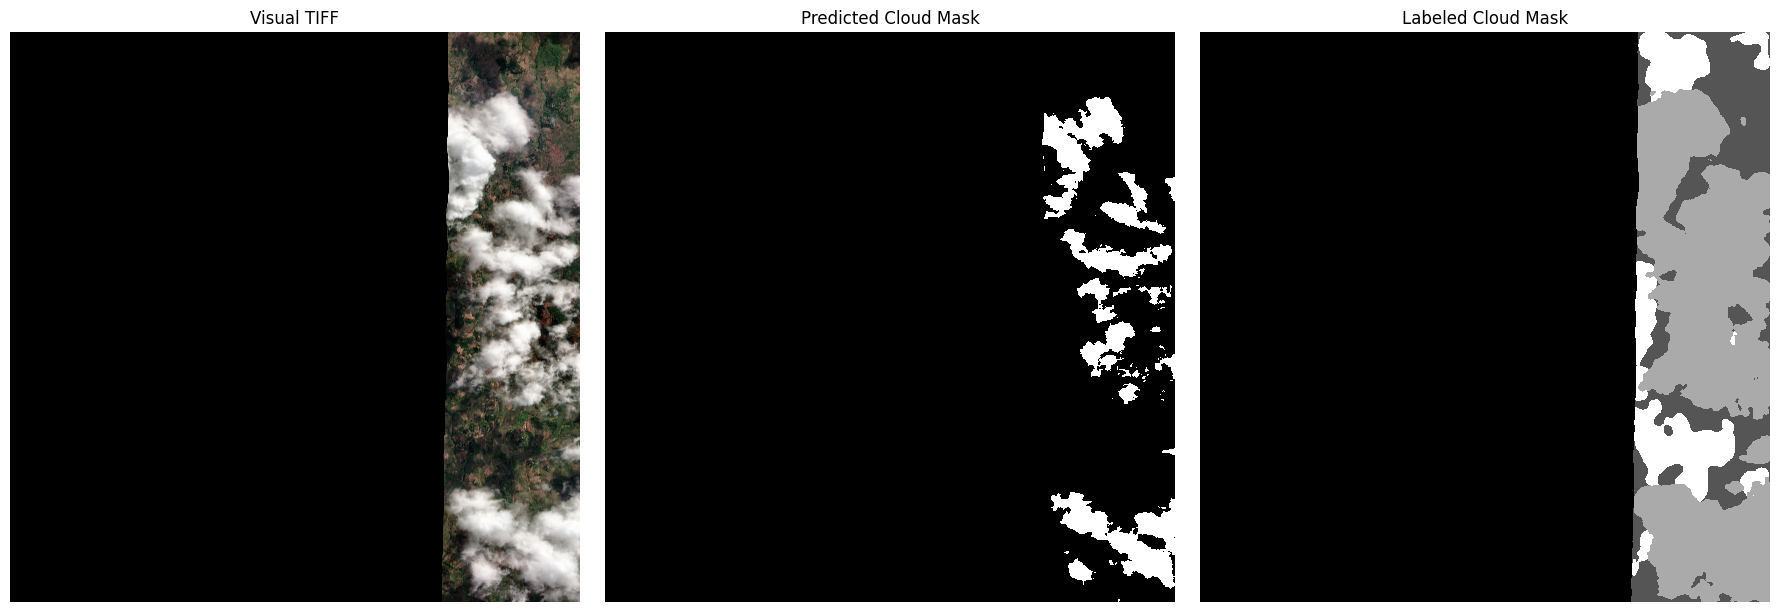

In [11]:
display_masks_side_by_side(
    "https://maxar-opendata.s3.amazonaws.com/events/cyclone-emnati22/ard/38/302000112032/2020-08-11/105001001F17C100-visual.tif",
    "/content/output_cloud_mask1.tif",
    "https://maxar-opendata.s3.amazonaws.com/events/cyclone-emnati22/ard/38/302000112032/2020-08-11/105001001F17C100-clouds.tif",
)

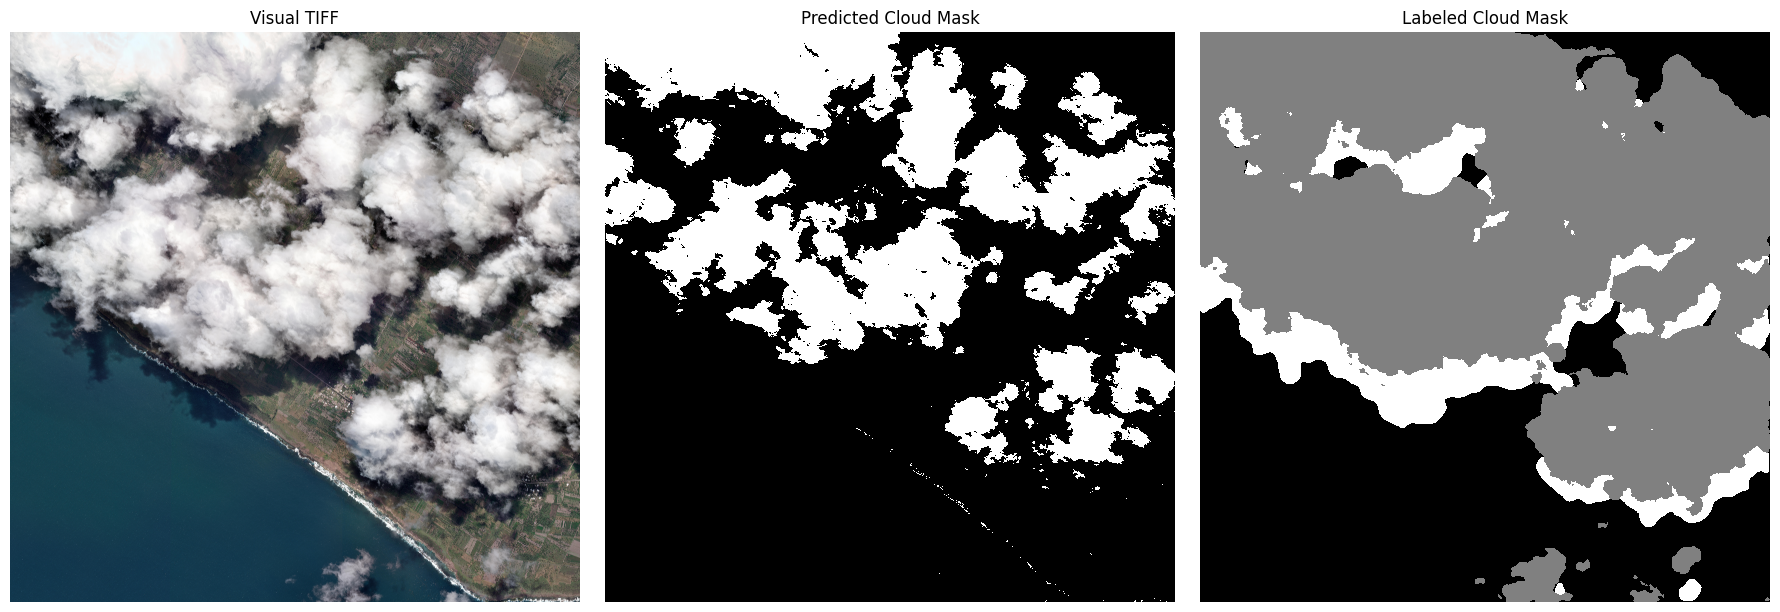

In [12]:
display_masks_side_by_side(
    "https://maxar-opendata.s3.amazonaws.com/events/tonga-volcano21/ard/01/300222120211/2022-01-18/10400100718A2000-visual.tif",
    "/content/output_cloud_mask2.tif",
    "https://maxar-opendata.s3.amazonaws.com/events/tonga-volcano21/ard/01/300222120211/2022-01-18/10400100718A2000-clouds.tif",
)

- dark channel prior pretty accurate for regular clouds
- might have trouble on detecting proper cloud edges
- however, might have false positives for surfaces that are brighter but not clouds, sand etc,
- could tweak threshold to be higher but that might also result in lower cloud detection around the cloud edges



In [13]:

# ---- Evaluation: compare the predicted mask against the provided mask -------------------------

def score_counts(tp, fp, fn, tn):
    d = lambda a, b: a / b if b else float("nan")
    return {
        "precision": d(tp, tp + fp),
        "recall": d(tp, tp + fn),
        "f1": d(2 * tp, 2 * tp + fp + fn),
        "iou": d(tp, tp + fp + fn),
        "accuracy": d(tp + tn, tp + fp + fn + tn),
    }
def evaluate_mask(predicted_mask_path, label_tiff_url, window_size=520):
    """Compare predicted cloud mask with the reference mask.

    Reference labels:
        1 = clear
        2 = cloud
        0 = NoData (ignored)
        3 = cloud shadow (ignored)

    Predicted mask:
        0 = clear
        1 = cloud
    """
    tp = fp = fn = tn = 0

    with rasterio.open(predicted_mask_path) as pred_src, \
         rasterio.open(label_tiff_url) as lab_src:

        if pred_src.width != lab_src.width or pred_src.height != lab_src.height:
            raise ValueError("Prediction and reference mask dimensions do not match.")

        for tile in get_windows(label_tiff_url, window_size, window_size):
            win = tile["window"]

            pred = pred_src.read(1, window=win)
            label = lab_src.read(1, window=win)

            # Evaluate only clear and cloud reference pixels.
            valid = (label == 1) | (label == 2)

            predicted_cloud = pred == 1
            reference_cloud = label == 2

            p = predicted_cloud[valid]
            g = reference_cloud[valid]

            tp += int((p & g).sum())
            fp += int((p & ~g).sum())
            fn += int((~p & g).sum())
            tn += int((~p & ~g).sum())

    out = score_counts(tp, fp, fn, tn)
    out.update(tp=tp, fp=fp, fn=fn, tn=tn)
    return out


In [15]:
metrics = evaluate_mask('/content/output_cloud_mask2.tif', label_tiff_url)
print("Overall evaluation metrics on Tonga scene:")
for k, v in metrics.items():
    print(f"  {k}: {v}")

Overall evaluation metrics on Tonga scene:
  precision: 0.9986242869600639
  recall: 0.5036839382369684
  f1: 0.6696242558469128
  iou: 0.5033346847985366
  accuracy: 0.6869604195553296
  tp: 1358151
  fp: 1871
  fn: 1338284
  tn: 1582798
